#### Testing SMOTE

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE

# Load the cleaned Heart Disease dataset (918 rows, target = HeartDisease)
df = pd.read_csv("../../HeartDisease_cleaned.csv")

Original class distribution:
HeartDisease
1    508
0    410
Name: count, dtype: int64


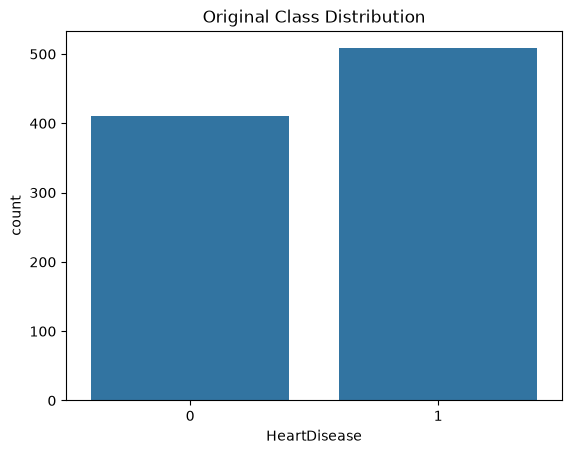

In [ ]:
# Display original class distribution
print("Original class distribution:")
print(df['HeartDisease'].value_counts())

# Visualize original distribution
sns.countplot(x='HeartDisease', data=df)
plt.title('Original Class Distribution')
plt.show()

# Original class distribution: 508 patients with heart disease (1) vs 410 without (0).
# The imbalance is mild, so SMOTE needs to create only 98 new rows.

In [ ]:
# Separate features and target
X = df.drop('HeartDisease', axis=1)
y = df['HeartDisease']

# if you want, you can also introduce a sampling strategy
# smote = SMOTE(sampling_strategy='minority', random_state=42)
# smote = SMOTE(sampling_strategy={3: 300, 4: 400, 5: 681, 6: 638, 7: 400, 8:300}, random_state=22)

# Apply SMOTE to the dataset
smote = SMOTE()

# use smote to sample a new version (Generate the new, balanced dataset)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Combine resampled features and target into a new DataFrame
df_resampled = pd.DataFrame(X_resampled, columns=X.columns)
df_resampled['HeartDisease'] = y_resampled

New class distribution after SMOTE:
HeartDisease
0    508
1    508
Name: count, dtype: int64


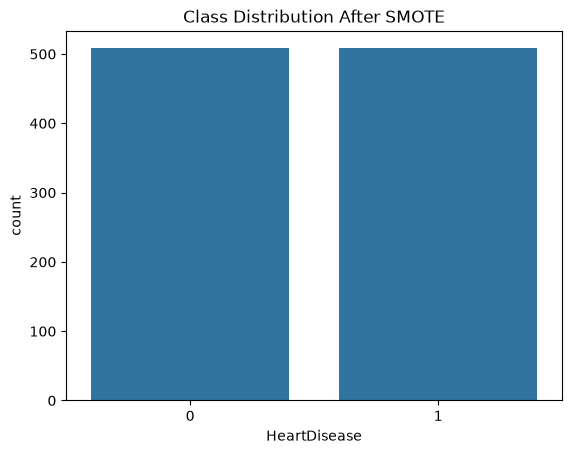

In [ ]:
# Display new class distribution
print("New class distribution after SMOTE:")
print(df_resampled['HeartDisease'].value_counts())

# Visualize new distribution
sns.countplot(x='HeartDisease', data=df_resampled)
plt.title('Class Distribution After SMOTE')
plt.show()

# Both classes now have 508 rows. 98 synthetic rows were added
# to class 0 (410 -> 508), total 918 -> 1016 rows.

In [ ]:
# No duplicate rows in the original data
df.duplicated().sum()

np.int64(0)

In [6]:
df_resampled.duplicated().sum()

np.int64(0)

After SMOTE the classes are balanced (508/508) and the basic statistics stay close to the original. This still needs to be tested with a machine learning model to see if it actually improves predictions. 

In [7]:
df.corr(numeric_only=True)['HeartDisease'].sort_values(ascending=True)

ST_Slope            -0.558771
ChestPainType_ATA   -0.401924
MaxHR               -0.400421
Cholesterol         -0.232741
ChestPainType_NAP   -0.212964
RestingECG_Normal   -0.091580
ChestPainType_TA    -0.054790
RestingECG_LVH       0.010670
RestingECG_ST        0.102527
RestingBP            0.107589
FastingBS            0.267291
Age                  0.282039
Sex                  0.305445
Oldpeak              0.403951
ExerciseAngina       0.494282
ChestPainType_ASY    0.516716
HeartDisease         1.000000
Name: HeartDisease, dtype: float64

In [ ]:
# Correlation of each feature with HeartDisease (original data)
df_resampled.corr(numeric_only=True)['HeartDisease'].sort_values(ascending=True)

ST_Slope            -0.539829
MaxHR               -0.390824
ChestPainType_ATA   -0.351224
Cholesterol         -0.248736
ChestPainType_NAP   -0.158272
RestingECG_Normal   -0.033877
ChestPainType_TA    -0.028404
RestingECG_LVH       0.047673
RestingBP            0.108952
RestingECG_ST        0.144996
Age                  0.285732
FastingBS            0.304142
Sex                  0.344595
Oldpeak              0.413320
ExerciseAngina       0.531201
ChestPainType_ASY    0.555157
HeartDisease         1.000000
Name: HeartDisease, dtype: float64

In [9]:
df.describe()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,0.789760,132.396514,198.799564,0.233115,136.809368,0.404139,0.887364,2.361656,0.553377,0.540305,0.188453,0.221133,0.050109,0.204793,0.601307,0.193900
std,9.432617,0.407701,18.514154,109.384145,0.423046,25.460334,0.490992,1.066570,0.607056,0.497414,0.498645,0.391287,0.415236,0.218289,0.403770,0.489896,0.395567
min,28.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.000000,1.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,54.000000,1.000000,130.000000,223.000000,0.000000,138.000000,0.000000,0.600000,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,60.000000,1.000000,140.000000,267.000000,0.000000,156.000000,1.000000,1.500000,3.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,77.000000,1.000000,200.000000,603.000000,1.000000,202.000000,1.000000,6.200000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [10]:
df_resampled.describe()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,HeartDisease
count,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000,1016.000000
mean,53.215551,0.752953,132.192913,202.564961,0.210630,137.549213,0.366142,0.844808,2.384843,0.494094,0.183071,0.205709,0.045276,0.189961,0.577756,0.175197,0.500000
std,9.398239,0.431507,18.293399,107.090007,0.407957,25.327443,0.481986,1.039426,0.607447,0.500211,0.386915,0.404418,0.208010,0.392463,0.494160,0.380323,0.500246
min,28.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,46.000000,1.000000,120.000000,177.750000,0.000000,120.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,54.000000,1.000000,130.000000,223.000000,0.000000,139.000000,0.000000,0.500000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.500000
75%,60.000000,1.000000,140.000000,268.000000,0.000000,156.000000,1.000000,1.500000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,77.000000,1.000000,200.000000,603.000000,1.000000,202.000000,1.000000,6.200000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [11]:

df.var(numeric_only=True)

Age                     88.974254
Sex                      0.166220
RestingBP              342.773903
Cholesterol          11964.891079
FastingBS                0.178968
MaxHR                  648.228614
ExerciseAngina           0.241073
Oldpeak                  1.137572
ST_Slope                 0.368517
HeartDisease             0.247420
ChestPainType_ASY        0.248646
ChestPainType_ATA        0.153105
ChestPainType_NAP        0.172421
ChestPainType_TA         0.047650
RestingECG_LVH           0.163030
RestingECG_Normal        0.239998
RestingECG_ST            0.156473
dtype: float64

In [12]:
# some changes here also, it seems
df_resampled.var(numeric_only=True)

Age                     88.326891
Sex                      0.186198
RestingBP              334.648462
Cholesterol          11468.269668
FastingBS                0.166429
MaxHR                  641.479349
ExerciseAngina           0.232311
Oldpeak                  1.080407
ST_Slope                 0.368992
ChestPainType_ASY        0.250211
ChestPainType_ATA        0.149703
ChestPainType_NAP        0.163554
ChestPainType_TA         0.043268
RestingECG_LVH           0.154027
RestingECG_Normal        0.244194
RestingECG_ST            0.144645
HeartDisease             0.250246
dtype: float64

The new data stays close to the original. Means, variances and min/max values are almost unchanged (for example Age mean 53.51 → 53.22, Cholesterol variance 11964.89 → 11468.27), and no duplicate rows were created, so the synthetic rows are new points and not copies of real patients. The correlations with HeartDisease also changed only slightly (for example ExerciseAngina 0.49 → 0.53, ST_Slope -0.56 → -0.54), and the ranking of the features stayed about the same.